In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

def BankChurn_data_reader(filename='Churn.csv'):
    data = pd.read_csv(filename)
    X = data.drop(['Exited'],axis = 1)
    y = data['Exited']
    return X, y

In [2]:
from sklearn.model_selection import train_test_split
import lightgbm as lgb
from sklearn.metrics import r2_score,f1_score
# define the characteristic function
def classification_kpi(G,S):
    """_summary_

    Args:
        G (nx.Graph): _description_
        S (list): list of nodes (list of columns)
    """
    cols = list(S)
    if len(cols) == 0:
        return 0
    else:
        X_train, X_test, y_train, y_test = train_test_split(X[cols], y, test_size=0.3, random_state=42)
        lgb_model = lgb.LGBMClassifier(verbose=-1)

        lgb_model.fit(X_train,y_train)
        lgb_pred = lgb_model.predict(X_test)
        f1 = f1_score(y_test, lgb_pred)
        return f1

In [3]:
# import shapG and necessary libraries
import networkx as nx
import shapG.shapley as shapley
import shapG.plot as shapGplot
from shapG.utils import corr_generator, create_minimal_edge_graph
import time

In [4]:
s = time.time()

In [5]:
# explain the model
X, y = BankChurn_data_reader('Churn.csv')
W = corr_generator(X)
A, W_new = create_minimal_edge_graph(W, version='v3')
G = nx.Graph(A)
shapley_value = shapley.shapG(G, m=3, f=classification_kpi, approximate_by_ratio=False)

100%|███████████████████████████████████████████| 10/10 [03:31<00:00, 21.12s/it]


In [6]:
e = time.time()
e-s

212.91736316680908

In [7]:
import seaborn as sns
import networkx as nx

# plot the networkx graph for W and W_new
def plot_graph(W, file_name=None):
    """_summary_

    Args:
        W (pd.DataFrame): weight matrix
    """
    G = nx.Graph(W)
    plt.figure(figsize=(20, 20))
    nx.draw(G, with_labels=True)
    if file_name is not None:
        plt.savefig(file_name, format='eps', dpi=300)
    plt.show()

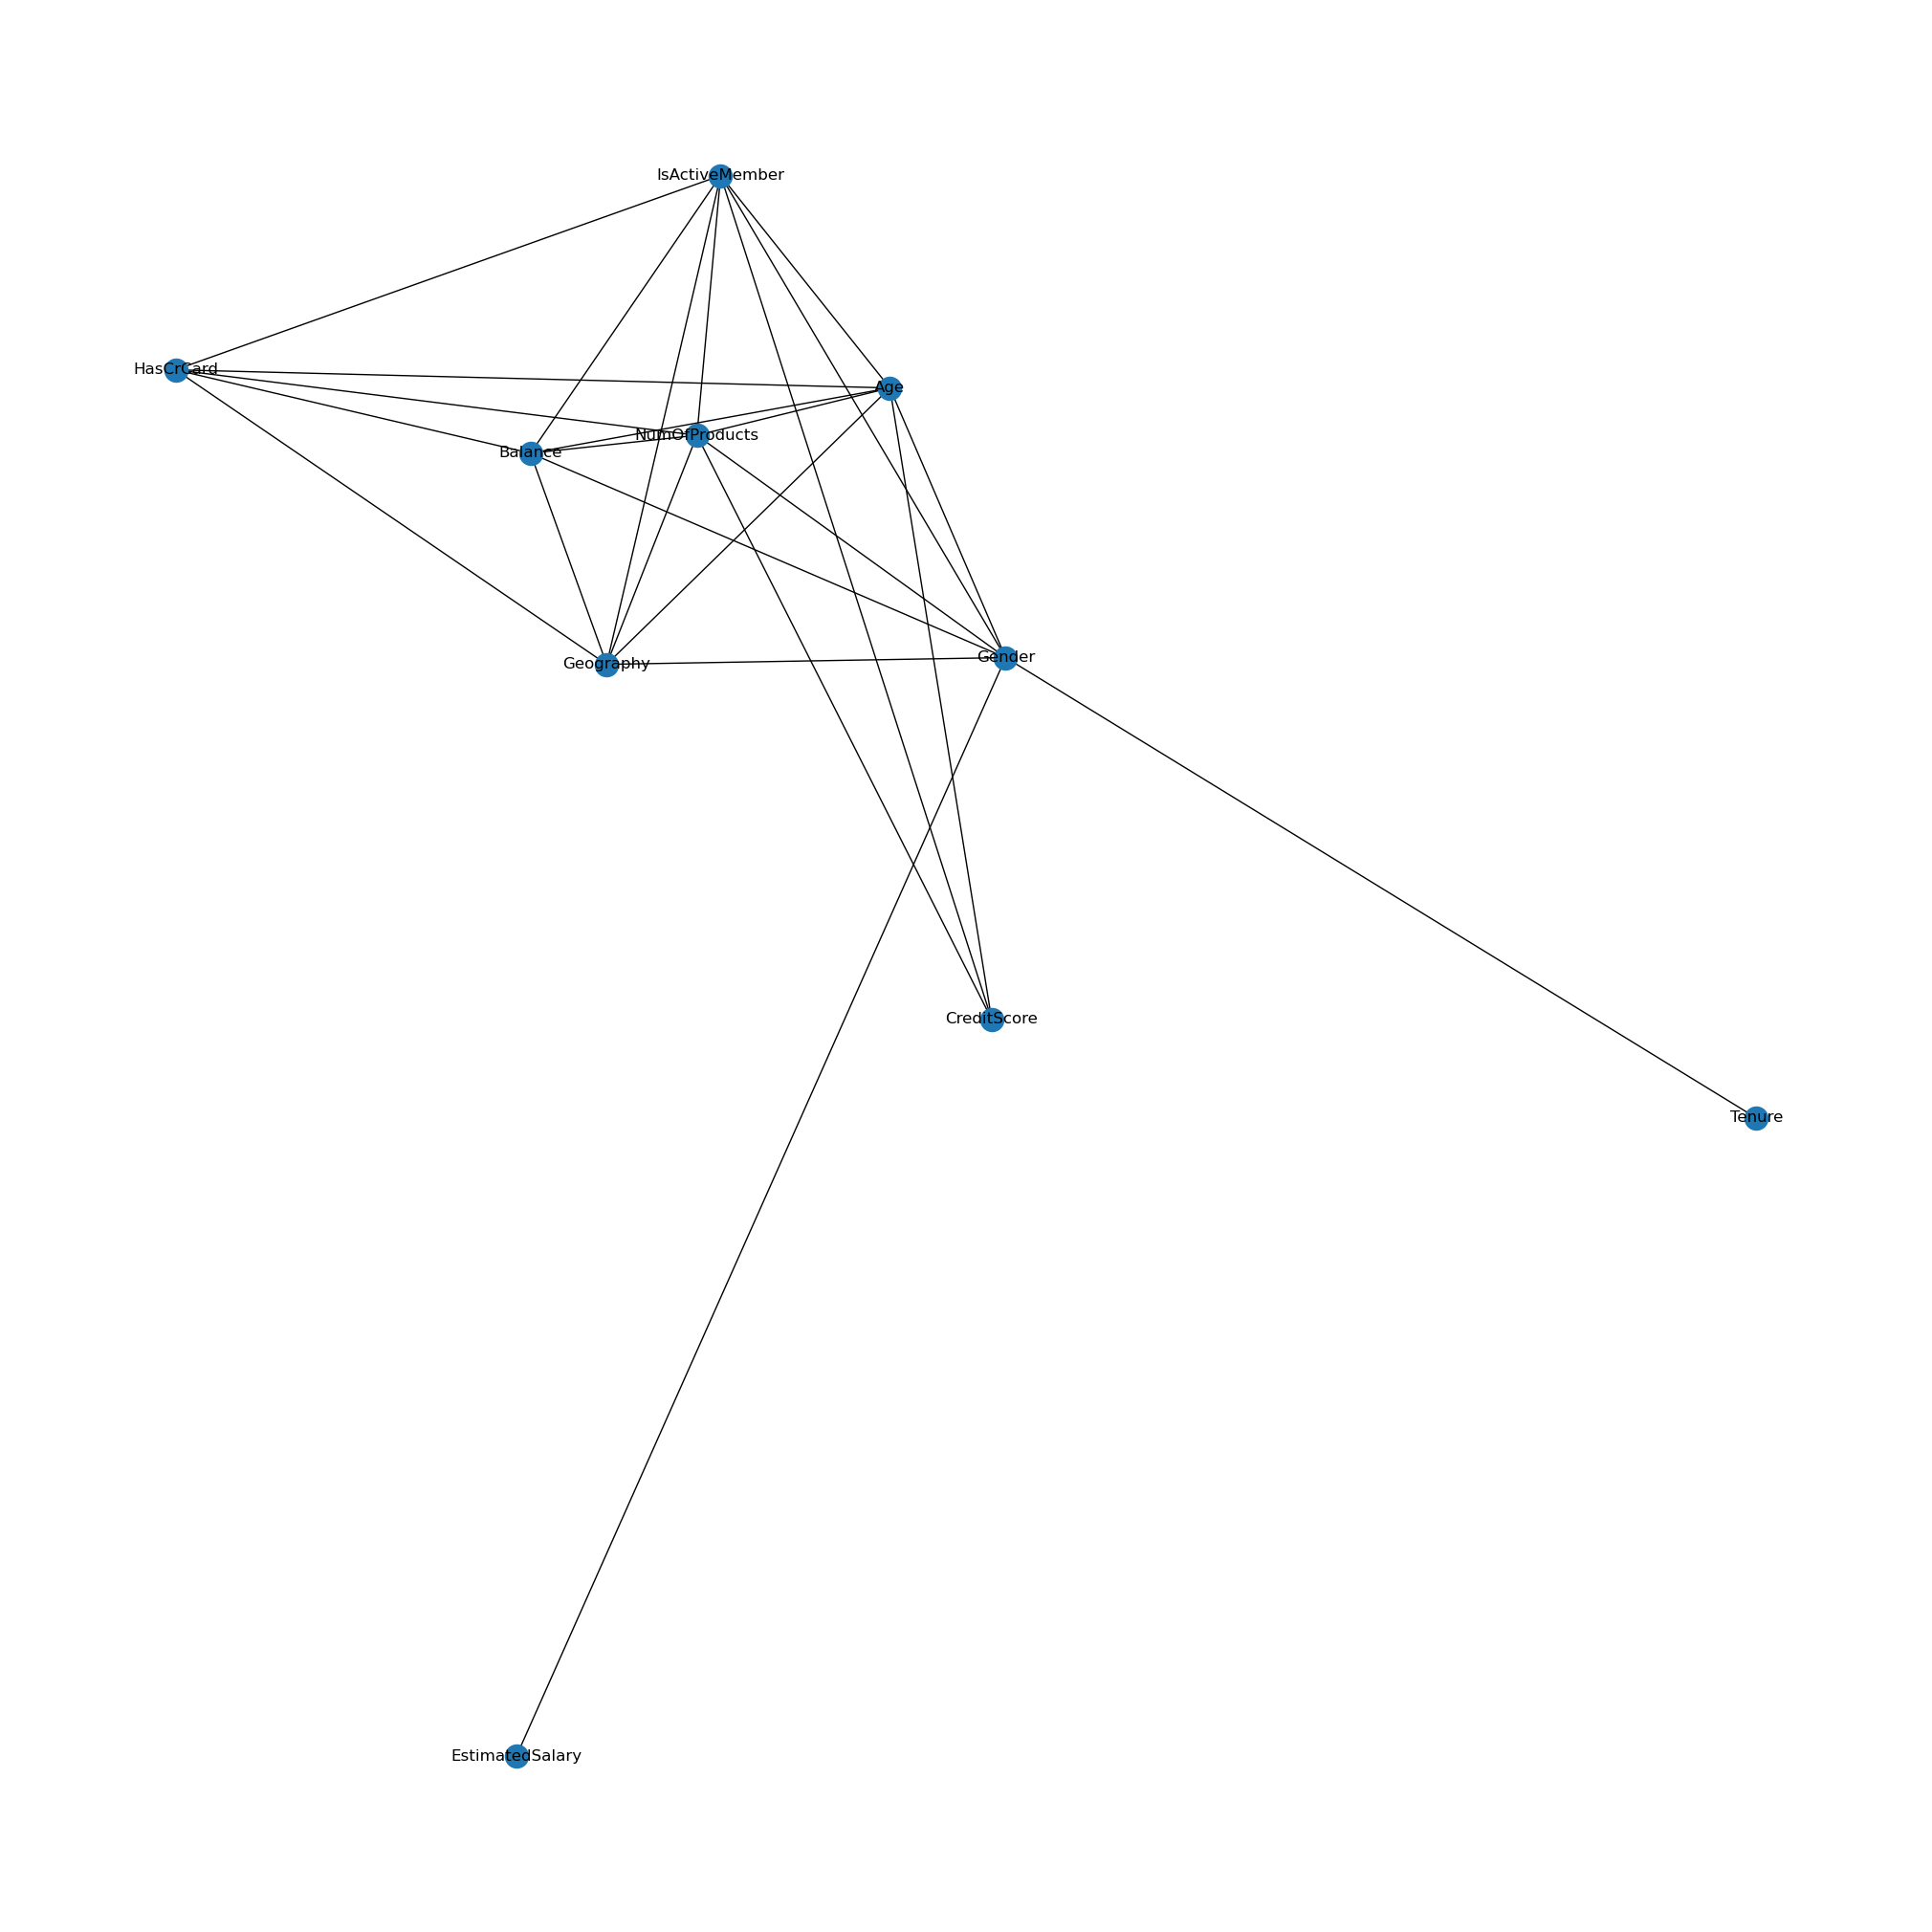

In [8]:
plot_graph(W_new, file_name=None)

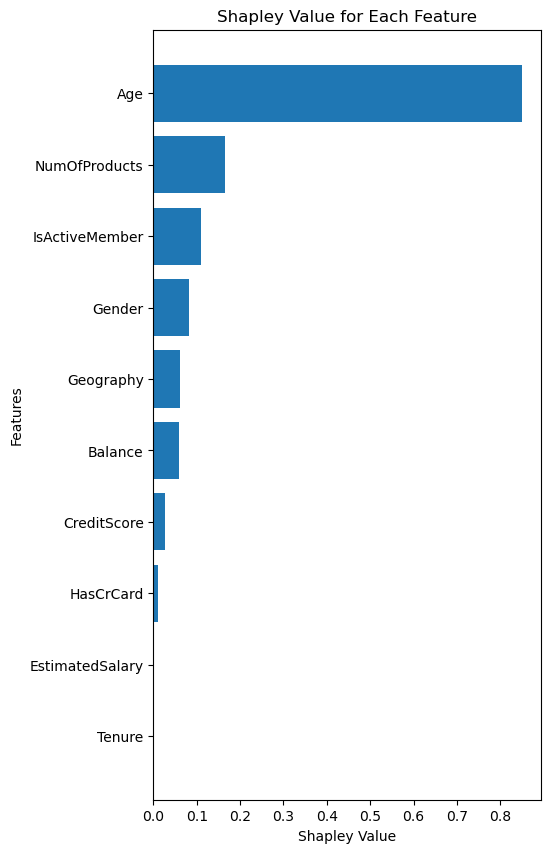

In [9]:
import matplotlib.pyplot as plt

# # Assuming results2[(0.1,10)] contains data represented in tuple form
# data = results[(0.05,3)]

# Sorting the data by values in descending order
sorted_data = sorted(shapley_value.items(), key=lambda x: x[1])

# Extracting the sorted data
labels = [item[0] for item in sorted_data]
values = [item[1] for item in sorted_data]

# Creating a horizontal bar chart with labels on the y-axis and values on the x-axis in descending order
plt.figure(figsize=(5, 10))
plt.barh(labels, values)  # Horizontal bar chart
plt.xlabel('Shapley Value')
plt.ylabel('Features')
plt.title('Shapley Value for Each Feature')
plt.show()

In [10]:
sorted_data

[('Tenure', 0.0),
 ('EstimatedSalary', 0.0),
 ('HasCrCard', 0.009480500171233294),
 ('CreditScore', 0.026001442430150894),
 ('Balance', 0.06006074725201206),
 ('Geography', 0.06034823415653269),
 ('Gender', 0.08209270088552269),
 ('IsActiveMember', 0.11033918696755055),
 ('NumOfProducts', 0.1659668249965402),
 ('Age', 0.851064164739701)]

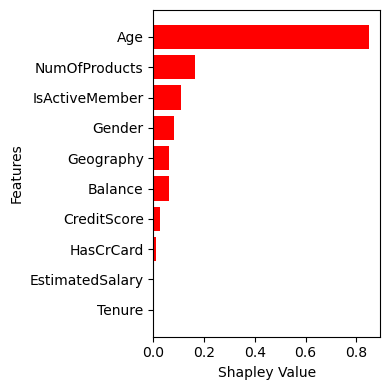

In [3]:
import matplotlib.pyplot as plt

# 提取特征名称和权重（按权重从大到小排序）
data = [('Tenure', 0.0),
 ('EstimatedSalary', 0.0),
 ('HasCrCard', 0.009480500171233294),
 ('CreditScore', 0.026001442430150894),
 ('Balance', 0.06006074725201206),
 ('Geography', 0.06034823415653269),
 ('Gender', 0.08209270088552269),
 ('IsActiveMember', 0.11033918696755055),
 ('NumOfProducts', 0.1659668249965402),
 ('Age', 0.851064164739701)]

labels, values = zip(*data)

plt.figure(figsize=(4, 4))

# 使用Matplotlib的barh()函数绘制条形图
plt.barh(labels, values, color='r')

plt.xlabel('Shapley Value')
plt.ylabel('Features')

# 使用tight_layout来调整图表以适应指定的图形大小
plt.tight_layout()

# 保存图像，确保DPI设置为300，并包括标签和边距
plt.savefig('shapG_bank_lgb.eps', format='eps', dpi=300, bbox_inches='tight')

plt.show()


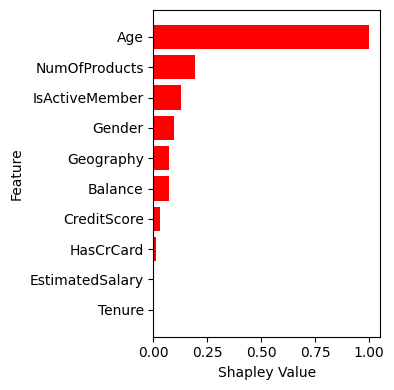

In [1]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import numpy as np

import matplotlib.pyplot as plt

data = [('Tenure', 0.0),
 ('EstimatedSalary', 0.0),
 ('HasCrCard', 0.009480500171233294),
 ('CreditScore', 0.026001442430150894),
 ('Balance', 0.06006074725201206),
 ('Geography', 0.06034823415653269),
 ('Gender', 0.08209270088552269),
 ('IsActiveMember', 0.11033918696755055),
 ('NumOfProducts', 0.1659668249965402),
 ('Age', 0.851064164739701)]

labels, values = zip(*data)
# 将权重转换为numpy数组
values = np.array(values).reshape(-1, 1)

# 使用MinMaxScaler进行归一化
scaler = MinMaxScaler()
normalized_values = scaler.fit_transform(values).flatten()

# 绘制条形图
plt.figure(figsize=(4, 4))

# 使用Matplotlib的barh()函数绘制条形图
plt.barh(labels, normalized_values, color='r')

plt.xlabel('Shapley Value')
plt.ylabel('Feature')

# 使用tight_layout来调整图表以适应指定的图形大小
plt.tight_layout()

# 保存图像，确保DPI设置为300，并包括标签和边距
plt.savefig('sshapG_bank_lgb_normalized.eps', format='eps', dpi=300, bbox_inches='tight')

plt.show()